In [1]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [54]:
# Параметры симуляции для MEEP
resolution = 20  # разрешение сетки (точек на длину волны)
wavelength = 3.7  # длина волны источника
X_cell_size = 250
Y_cell_size = 200*2
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X)]
symmetries = [mp.Mirror(mp.Y)]
sources = [mp.Source(
    mp.ContinuousSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=mp.Vector3(x=-X_cell_size/2 +conf.in_pml, y=Y_cell_size/2, z=0),
    size=mp.Vector3(x=0, y=Y_cell_size, z=0),
)]

In [55]:
# Все параметры касающиеся определения геометрии
M = 20 # число радиальных слоёв.
k = 2 * np.pi / wavelength # волновое число
f = 0.25 * 1000 # focal length 10mm
Q = 120 # детализация
w = 0.2 # 200 nm (расстояние промежутка)
epsilon = 0.02  # Задайте точность, с которой y1 должен быть равен w

centers = []
width_curves = []
geometry = []

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)


# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))
def zero_derivative (n):
    calculation = np.sqrt((4 * f * n * np.pi)/k)
    return calculation

# Main loop for layers
for m in range(M):
    center = zero_derivative(m)
    centers.append(center)
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m] - 0.01, Q)
    # Compute y values by integration
    y = np.array([quad(fun, rt0, xi)[0] for xi in x])
    xt = x.copy()
    ip = np.argmin(y)
    y1 = y - y[ip]

    # Найти первое значение x, при котором y1 примерно равно w
    index = np.argmax(np.abs(y1 - w) < epsilon)
    if np.abs(y1[index] - w) < epsilon:
        x_first_close_to_w = x[index]
    else:
        raise ValueError(f"Для слоя {m} значение x, соответствующее y1 ≈ {w}, не найдено. Увеличь Q!")

    dx = abs(2*(center - x[index]))
    width_curves.append(dx)

    print(f'Параметры ячейки для порядка {m}: width = {dx:.2f} | center = {center:.2f}')

Параметры ячейки для порядка 0: width = 13.80 | center = 0.00
Параметры ячейки для порядка 1: width = 3.40 | center = 43.01
Параметры ячейки для порядка 2: width = 2.80 | center = 60.83
Параметры ячейки для порядка 3: width = 2.61 | center = 74.50
Параметры ячейки для порядка 4: width = 2.31 | center = 86.02
Параметры ячейки для порядка 5: width = 2.15 | center = 96.18
Параметры ячейки для порядка 6: width = 2.06 | center = 105.36
Параметры ячейки для порядка 7: width = 2.01 | center = 113.80
Параметры ячейки для порядка 8: width = 1.98 | center = 121.66
Параметры ячейки для порядка 9: width = 1.97 | center = 129.03
Параметры ячейки для порядка 10: width = 1.85 | center = 136.01
Параметры ячейки для порядка 11: width = 1.86 | center = 142.65
Параметры ячейки для порядка 12: width = 1.77 | center = 149.00
Параметры ячейки для порядка 13: width = 1.79 | center = 155.08
Параметры ячейки для порядка 14: width = 1.71 | center = 160.93
Параметры ячейки для порядка 15: width = 1.65 | center =

In [56]:
# Зальем теперь это все в геометрию
for m in range(M):
    geometry.append(mp.Block(
        material=conf.in_material,
        size=mp.Vector3(conf.at_hei, width_curves[m], 0),
        center=mp.Vector3(x=-X_cell_size/2+conf.in_pml + conf.at_hei/2 + conf.in_gap, y=centers[m], z=0)
    ))

In [57]:
geometry[0].center

Vector3<-121.0, 0.0, 0.0>

In [58]:
len(geometry)

20

     block, center = (-121,0,0)
          size (2,13.7967,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,43.0116,0)
          size (2,3.39969,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,60.8276,0)
          size (2,2.798,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,74.4983,0)
          size (2,2.61132,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,86.0233,0)
          size (2,2.3088,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,96.1769,0)
          size (2,2.15115,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielec

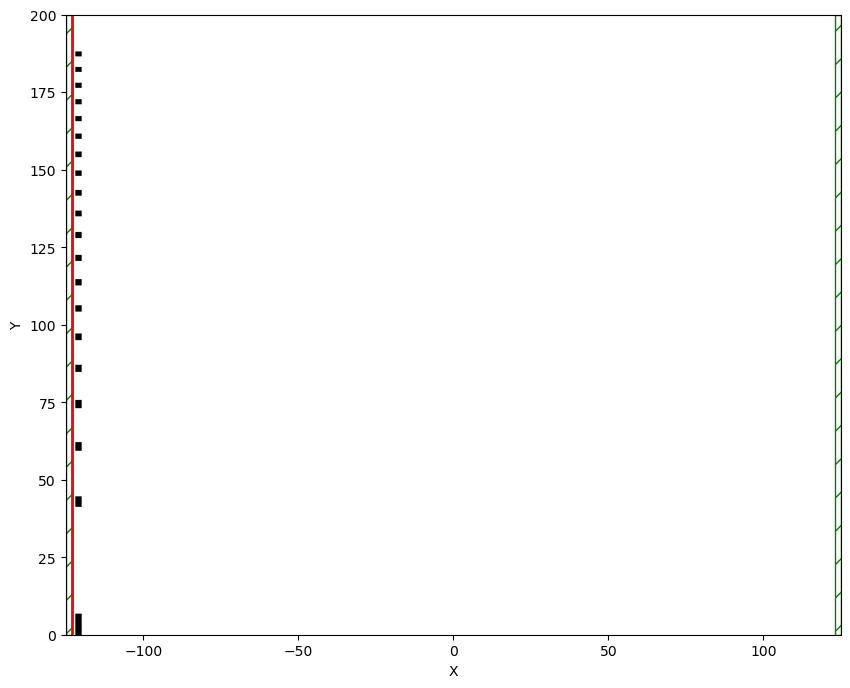

In [59]:
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=resolution,
    symmetries = symmetries,
)

plt.figure(figsize=(10, 10))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,cell[1]/4, 0), size=mp.Vector3(cell[0], cell[1]/2,0)) 
)

plt.savefig("simulation_plot.png", dpi = 100)  # Сохранение изображения в файл
plt.show()  # Отображение изображения


In [60]:
# Запись полей
field_data = []

In [61]:
def get_field(sim):
    field_data.append(np.abs(sim.get_array(center=mp.Vector3(), size=cell, component=mp.Ez))**2)

-----------
Initializing structure...
Halving computational cell along direction y
time for choose_chunkdivision = 0.00153494 s
Working in 2D dimensions.
Computational cell is 250 x 400 x 0 with resolution 20
     block, center = (-121,0,0)
          size (2,13.7967,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,43.0116,0)
          size (2,3.39969,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,60.8276,0)
          size (2,2.798,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,74.4983,0)
          size (2,2.61132,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-121,86.0233,0)
          size (2,2.3088,0)
          axes (1,0,0), (

FloatProgress(value=0.0, description='0% done ', max=200.0)

Meep progress: 0.9750000000000001/200.0 = 0.5% done in 4.1s, 827.4s to go
on time step 39 (time=0.975), 0.103876 s/step
Meep progress: 2.25/200.0 = 1.1% done in 8.1s, 711.5s to go
on time step 90 (time=2.25), 0.0792409 s/step
Meep progress: 3.35/200.0 = 1.7% done in 12.1s, 712.5s to go
on time step 134 (time=3.35), 0.0918605 s/step
Meep progress: 4.425/200.0 = 2.2% done in 16.2s, 714.3s to go
on time step 177 (time=4.425), 0.0935843 s/step
Meep progress: 5.5/200.0 = 2.8% done in 20.2s, 713.5s to go
on time step 220 (time=5.5), 0.0932963 s/step
Meep progress: 6.6000000000000005/200.0 = 3.3% done in 24.2s, 710.5s to go
on time step 264 (time=6.6), 0.0925299 s/step
Meep progress: 7.675000000000001/200.0 = 3.8% done in 28.3s, 709.0s to go
on time step 307 (time=7.675), 0.0941342 s/step
Meep progress: 8.75/200.0 = 4.4% done in 32.4s, 707.7s to go
on time step 350 (time=8.75), 0.0949194 s/step
Meep progress: 9.825000000000001/200.0 = 4.9% done in 36.4s, 704.7s to go
on time step 393 (time=9.

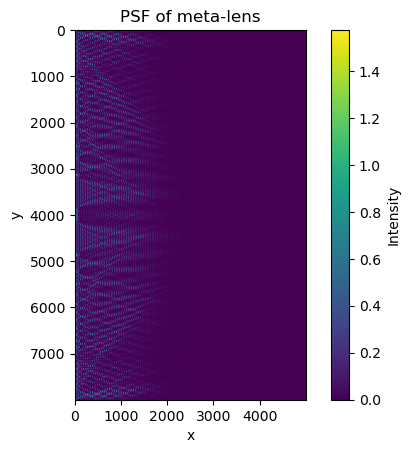

In [62]:
sim.run(mp.at_end(get_field), until=200)

# Построение PSF
field_data = np.array(field_data[-1])
plt.imshow(field_data.T)
plt.colorbar(label="Intensity")
plt.title("PSF of meta-lens")
plt.xlabel("x")
plt.ylabel("y")
plt.show()